In [2]:
from wordcloud import WordCloud
import random

In [63]:
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

In [3]:
import pandas as pd
import numpy as np
import re
import math

import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [4]:
pink_colors = ["#FFD1DC", "#FFB6C1", "#FF9BB5", "#FF82AB", "#FF00FF", "#EE1289", "#D02090", "#DA70D6", "#9370DB", "#8A2BE2", "#9400D3", "#9932CC", "#8B008B"]

In [5]:
df = pd.read_csv('data.csv')

In [6]:
df.head()

,index,title,genre,summary
0,0,Drowned Wednesday,fantasy,Drowned Wednesday is the first Trustee among ...
1,1,The Lost Hero,fantasy,"As the book opens, Jason awakens on a school ..."
2,2,The Eyes of the Overworld,fantasy,Cugel is easily persuaded by the merchant Fia...
3,3,Magic's Promise,fantasy,The book opens with Herald-Mage Vanyel return...
4,4,Taran Wanderer,fantasy,Taran and Gurgi have returned to Caer Dallben...


In [7]:
df = df.drop(columns=['index'])

In [8]:
df.shape

(4657, 3)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4657 entries, 0 to 4656
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    4657 non-null   object
 1   genre    4657 non-null   object
 2   summary  4657 non-null   object
dtypes: object(3)
memory usage: 109.3+ KB


In [10]:
df.describe(include="O")

,title,genre,summary
count,4657,4657,4657
unique,4296,10,4542
top,Bloodline,thriller,The incredible true story of the women who fou...
freq,4,1023,3


### пропуски

In [11]:
df.isnull().sum()

title      0
genre      0
summary    0
dtype: int64

### дубликаты

In [12]:
df.duplicated().sum()

np.int64(17)

In [13]:
df[df.duplicated()]

,title,genre,summary
3038,The Radium Girls: The Dark Story of America's ...,history,The incredible true story of the women who fou...
3624,A Lie for a Lie,sports,From the New York Times bestselling author of ...
3625,Rookie Move,sports,The first novel in a sexy new series featuring...
3626,The Raven King,sports,"The Foxes are a fractured mess, but their late..."
3627,The King's Men,sports,Neil Josten is out of time. He knew when he ca...
3628,The Play,sports,A brand-new standalone novel in the New York T...
3629,Hands Down,sports,"Before he was Big Texas, he was Zac the Snack ..."
3630,Taking a Shot,sports,"If you want to score, you have to get in the g..."
3631,What I Talk About When I Talk About Running,sports,"In 1982, having sold his jazz bar to devote hi..."
3632,Changing the Game,sports,Sports agent Liz Darnell will do anything to w...


In [14]:
df = df.drop_duplicates()

In [15]:
genre_counts = df['genre'].value_counts()

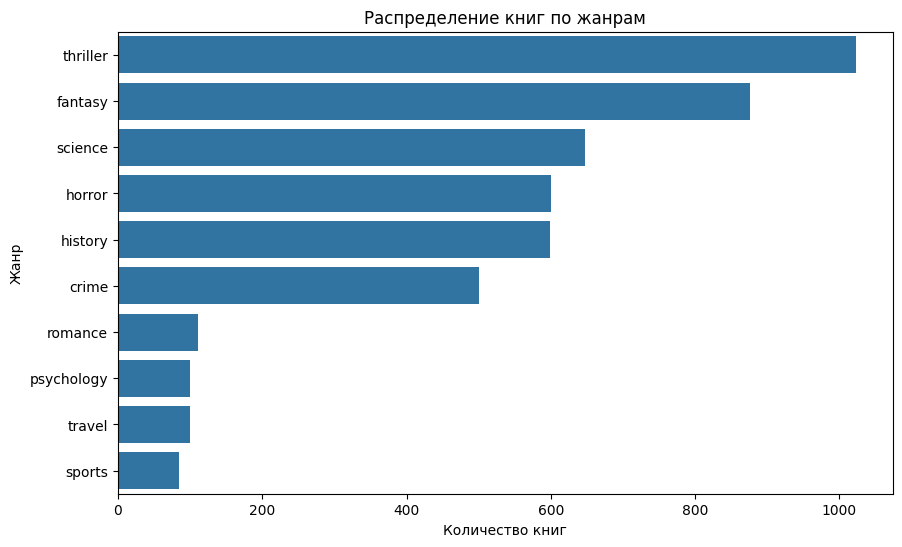

In [16]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='genre', order=genre_counts.index)
plt.title('Распределение книг по жанрам')
plt.xlabel('Количество книг')
plt.ylabel('Жанр')
plt.show()

In [17]:
df['title_length'] = df['title'].str.len()
df['summary_length'] = df['summary'].str.len()

Длина заголовков

In [18]:
df['title_length'].describe()

count    4640.000000
mean       19.325647
std        14.591063
min         2.000000
25%        12.000000
50%        16.000000
75%        21.000000
max       166.000000
Name: title_length, dtype: float64

Длина кратких содержаний

In [19]:
df['summary_length'].describe()

count     4640.000000
mean      2110.620259
std       2529.434193
min         11.000000
25%        698.750000
50%       1145.000000
75%       2569.750000
max      31263.000000
Name: summary_length, dtype: float64

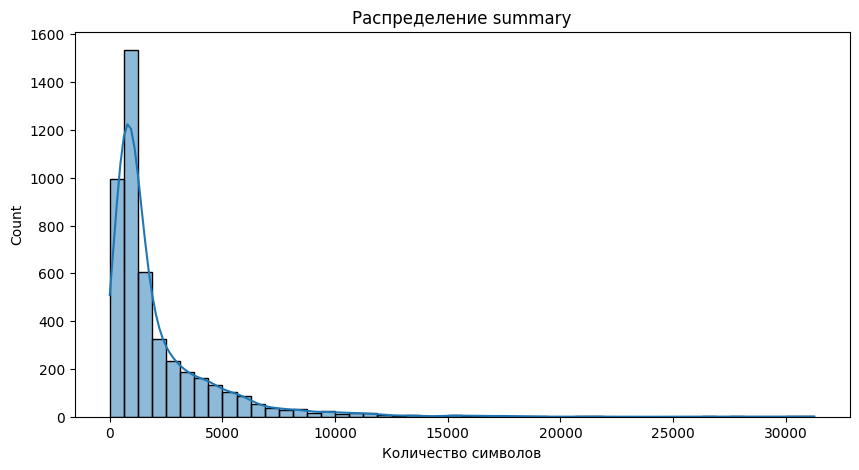

In [20]:
plt.figure(figsize=(10, 5))
sns.histplot(df['summary_length'], bins=50, kde=True)
plt.title('Распределение summary')
plt.xlabel('Количество символов')
plt.show()

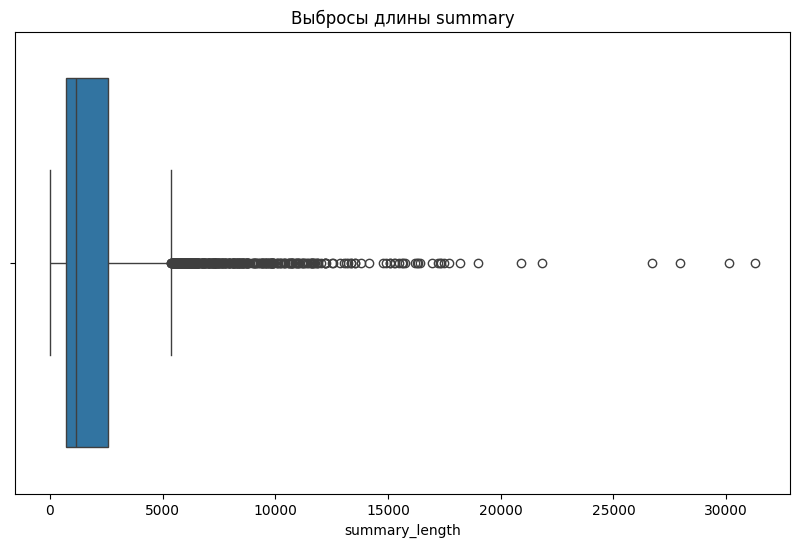

In [21]:
plt.figure(figsize=(10, 6))
sns.boxplot(x=df["summary_length"])
plt.title("Выбросы длины summary")
plt.show()

In [22]:
(df['summary_length'] > 10000).sum()

np.int64(90)

In [23]:
df[df['summary_length'] > 10000].head()

,title,genre,summary,title_length,summary_length
30,Dragon War,fantasy,"The Boneless King captures Shimmer, Monkey, a...",10,10608
46,A Feast for Crows,fantasy,The War of the Five Kings is slowly coming to...,17,11654
69,Neverwinter,fantasy,The story begins shortly after the events occ...,11,11855
88,The Will of the Empress,fantasy,The primary plot of the novel is the struggle...,23,10350
112,The Way of Shadows,fantasy,Azoth is an orphan who lives in the Warrens o...,18,10785


### Предобработка и векторизация заголовков

In [24]:
def clean_text(text):
    text = str(text).lower() 
    text = re.sub(r'[^a-z\s]', '', text)
    return text

In [25]:
df['clean_title'] = df['title'].apply(clean_text)

Подготовка мешка слов с помощью CountVectorizer

In [26]:
count_vectorizer = CountVectorizer(stop_words='english', min_df=2)

In [27]:
X_count = count_vectorizer.fit_transform(df['clean_title'])

In [28]:
X_count.shape

(4640, 1558)

Подготовка с использованием меры TF-IDF

In [29]:
tfidf_vectorizer = TfidfVectorizer(stop_words='english', min_df=2)

In [30]:
X_tfidf = tfidf_vectorizer.fit_transform(df['clean_title'])

In [31]:
X_tfidf.shape

(4640, 1558)

### Кластеризация и визуализация 

#### Кластеризация CountVectorizer

In [32]:
kmeans_count = KMeans(n_clusters=10, random_state=42, n_init=10)
df['cluster_count'] = kmeans_count.fit_predict(X_count)

In [33]:
pca_count = PCA(n_components=2)
coords_count = pca_count.fit_transform(X_count.toarray())

In [34]:
ari_count = adjusted_rand_score(df['genre'], df['cluster_count'])

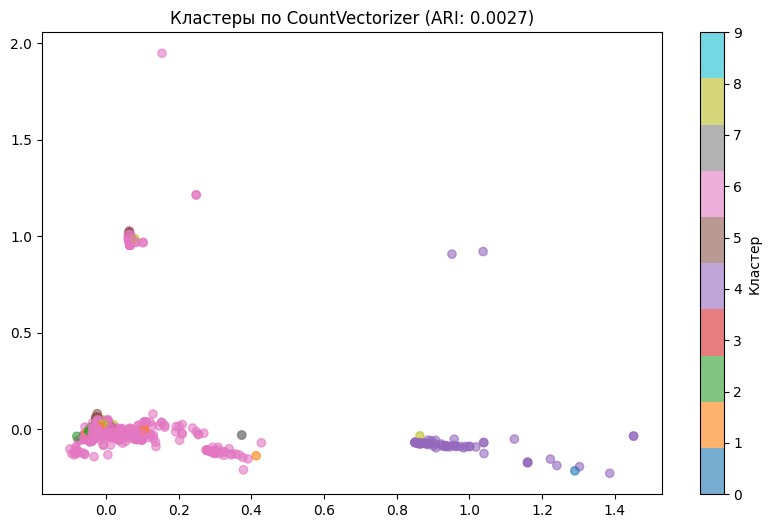

In [35]:
plt.figure(figsize=(10, 6))
plt.scatter(coords_count[:, 0], coords_count[:, 1], c=df['cluster_count'], cmap='tab10', alpha=0.6)
plt.title(f"Кластеры по CountVectorizer (ARI: {ari_count:.4f})")
plt.colorbar(label='Кластер')
plt.show()

In [36]:
def plot_wordcloud(words, title):
    wordcloud = WordCloud(width=800, height=400, background_color='white', color_func=lambda *args, **kwargs: random.choice(pink_colors)).generate(' '.join(words))
    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title, fontsize=20)
    plt.show()

#### Кластеризация TfidfVectorizer

In [37]:
kmeans_tfidf = KMeans(n_clusters=10, random_state=42, n_init=10)
df['cluster_tfidf'] = kmeans_tfidf.fit_predict(X_tfidf)

In [38]:
pca_tfidf = PCA(n_components=2)
coords_tfidf = pca_tfidf.fit_transform(X_tfidf.toarray())

In [39]:
ari_tfidf = adjusted_rand_score(df['genre'], df['cluster_tfidf'])

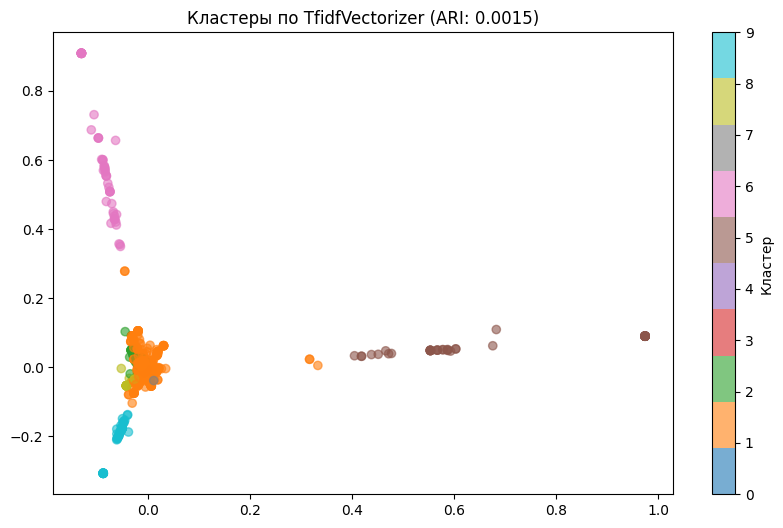

In [40]:
plt.figure(figsize=(10, 6))
plt.scatter(coords_tfidf[:, 0], coords_tfidf[:, 1], c=df['cluster_tfidf'], cmap='tab10', alpha=0.6)
plt.title(f"Кластеры по TfidfVectorizer (ARI: {ari_tfidf:.4f})")
plt.colorbar(label='Кластер')
plt.show()

### Улучшенная модель

#### Векторизация с N-граммами

Создаем вектор из слов и словосочетаний (от 1 до 2 слов)

In [41]:
tfidf_ngram = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=3, max_df=0.5)
X_ngram = tfidf_ngram.fit_transform(df['clean_title'])

In [42]:
kmeans_ngram = KMeans(n_clusters=10, random_state=42)
df['opt_cluster'] = kmeans_ngram.fit_predict(X_ngram)

In [96]:
ari_ngram = adjusted_rand_score(df['genre'], df['opt_cluster'])

In [94]:
silhouette_score(X_ngram, df['opt_cluster'])

0.14526007793675355

In [44]:
pca_ngram = PCA(n_components=2)
coords_ngram = pca_ngram.fit_transform(X_ngram.toarray())

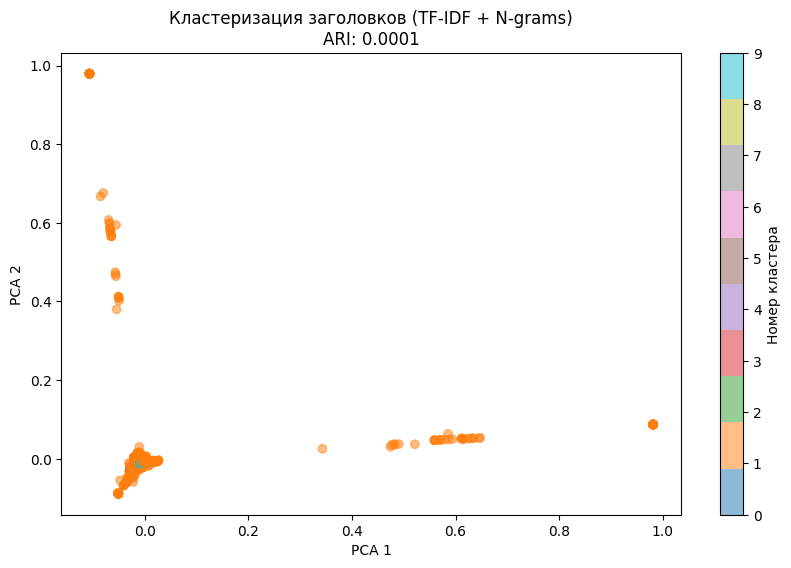

In [45]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(coords_ngram[:, 0], coords_ngram[:, 1], 
                      c=df['opt_cluster'], cmap='tab10', alpha=0.5)

plt.colorbar(scatter, label='Номер кластера')
plt.title(f"Кластеризация заголовков (TF-IDF + N-grams)\nARI: {ari_ngram:.4f}")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()

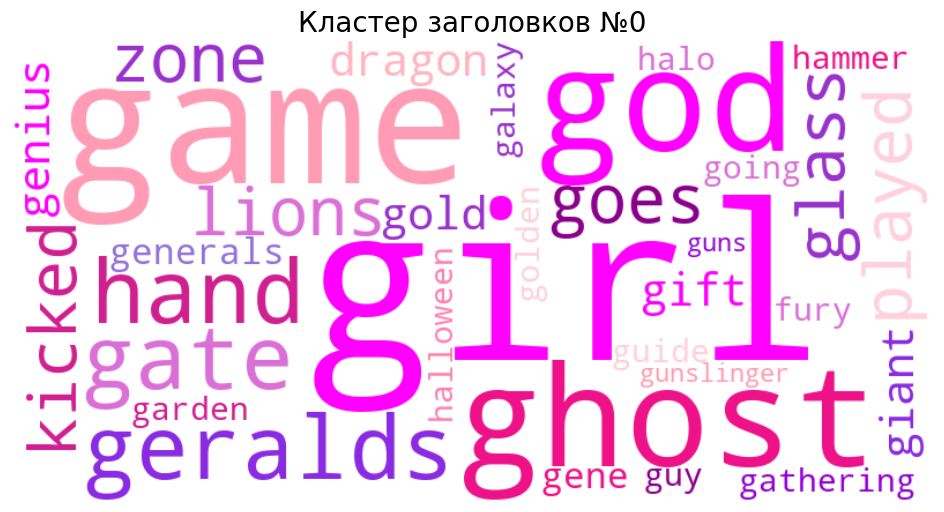

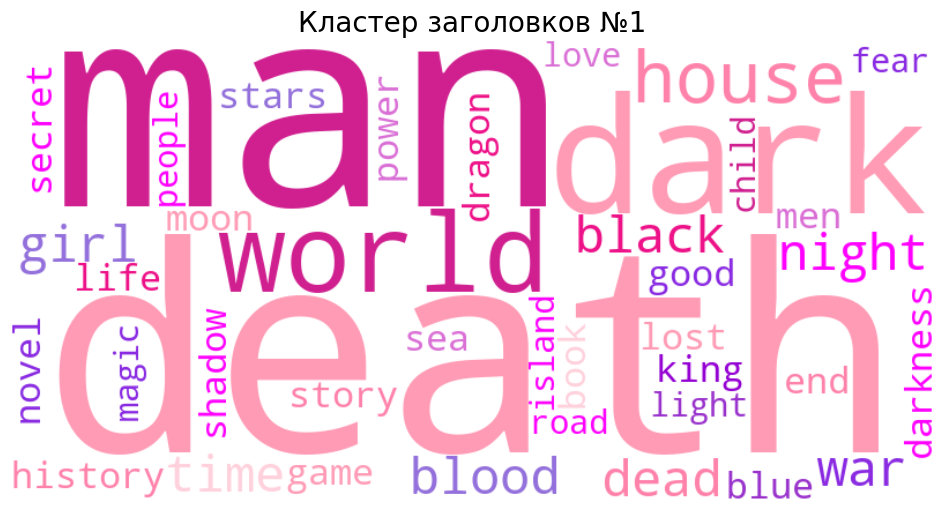

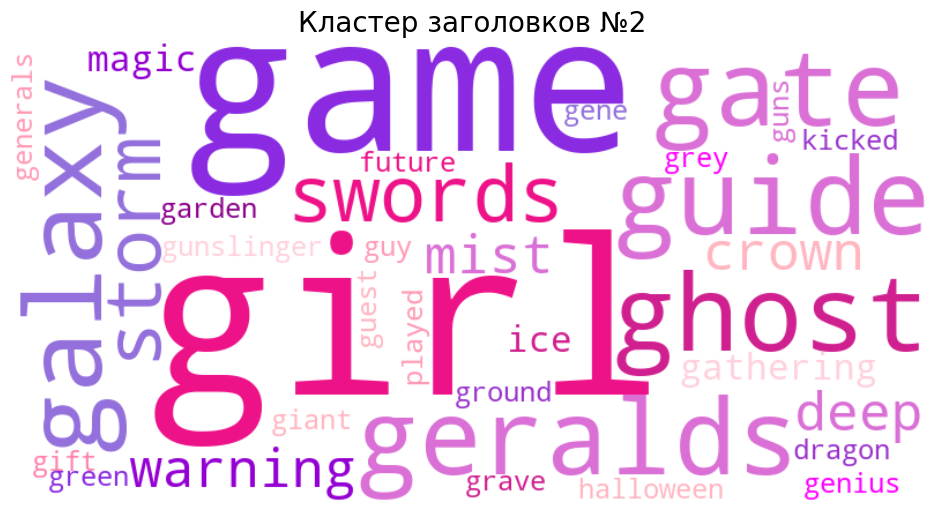

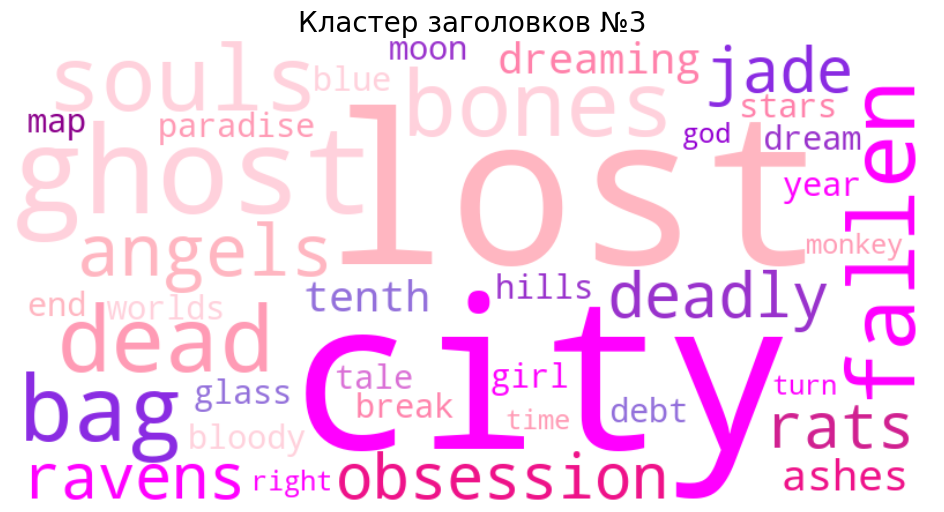

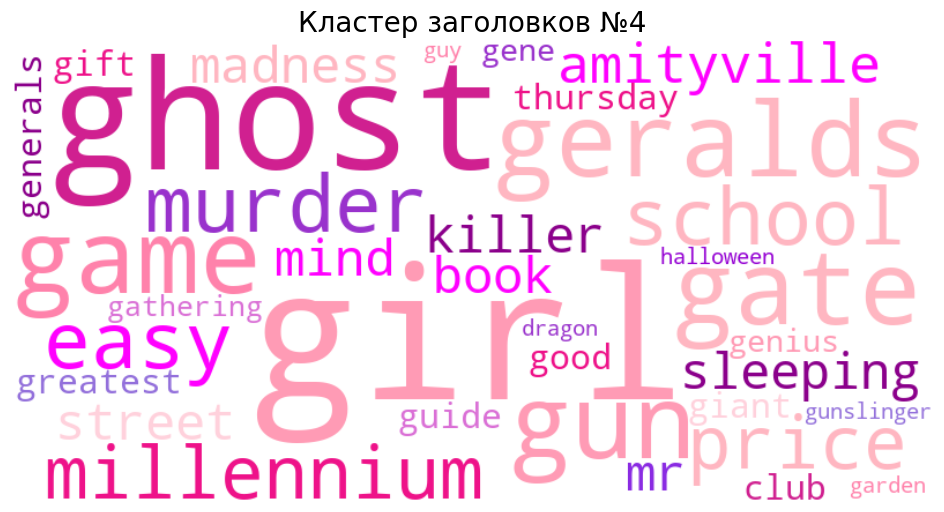

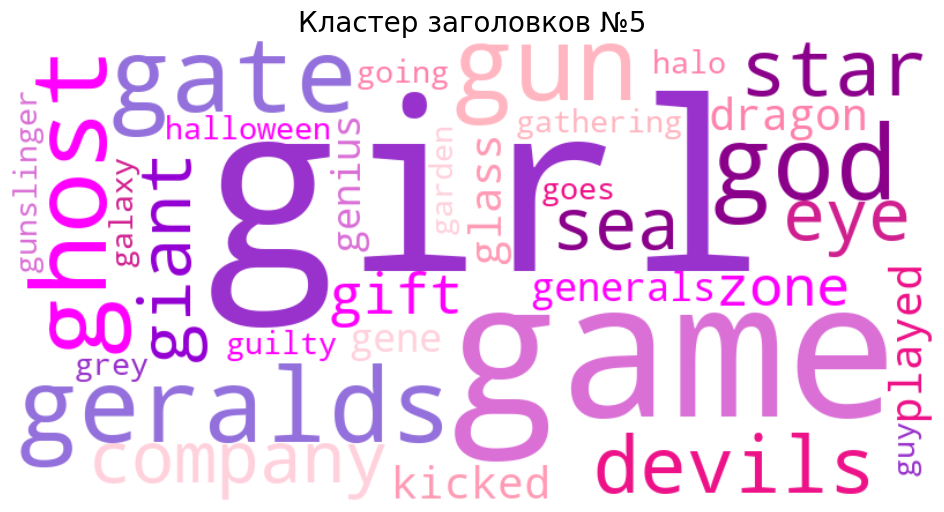

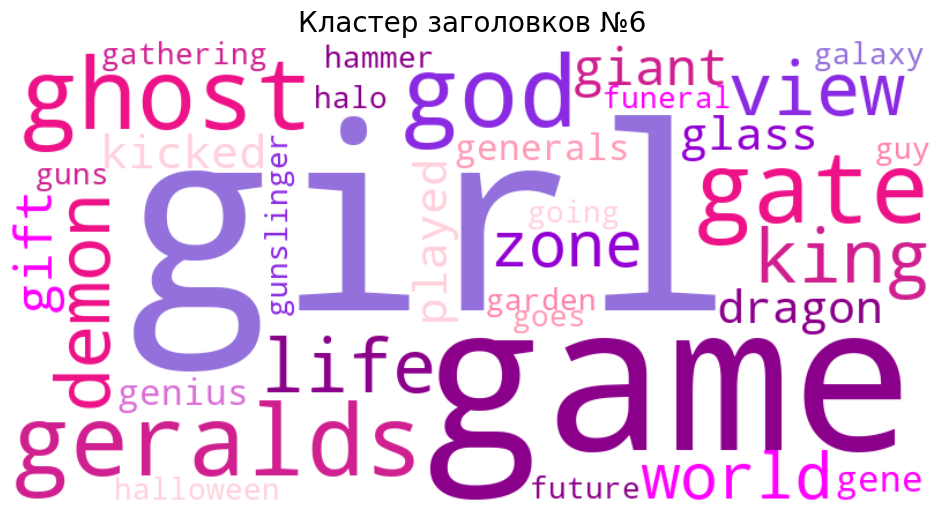

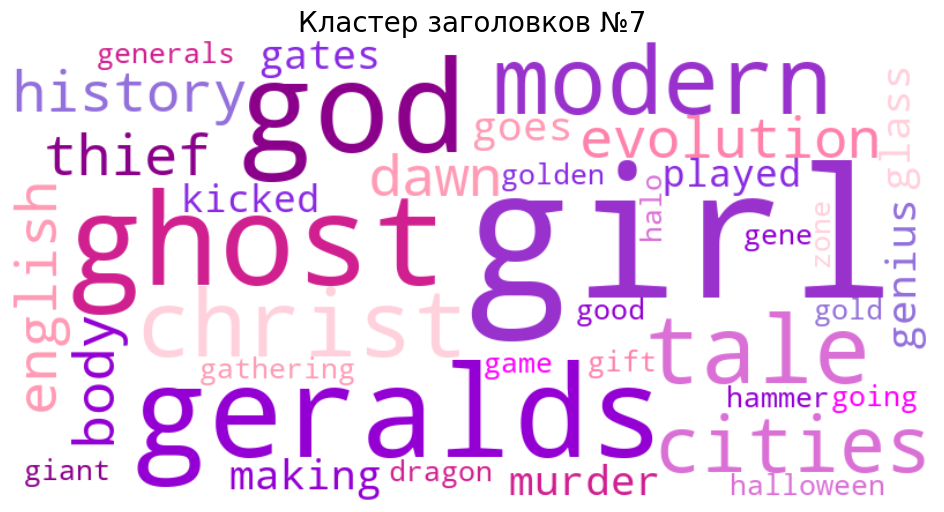

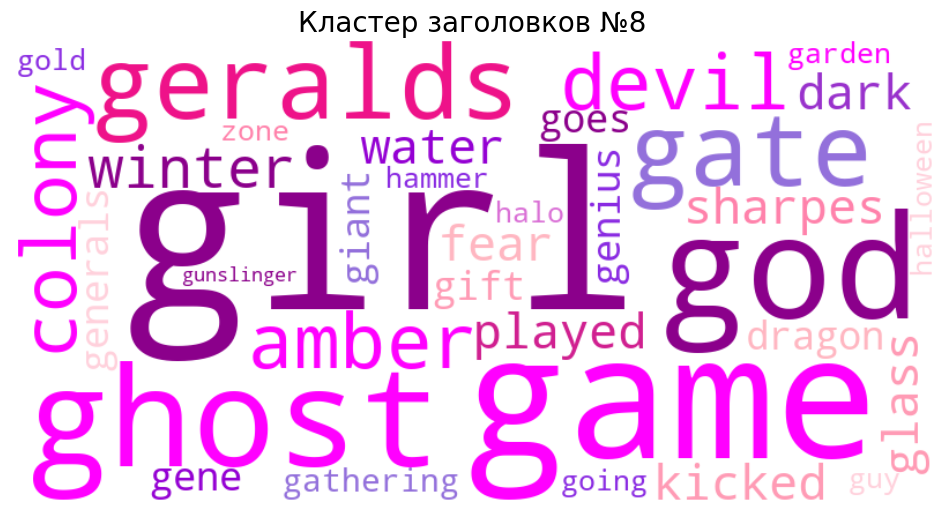

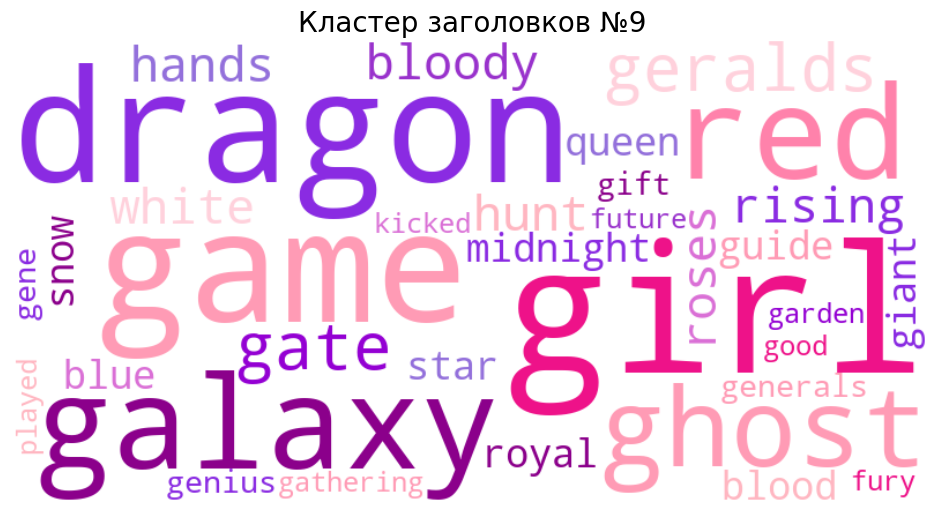

In [46]:
# Извлекаем названия признаков (слов/биграмм)
feature_names_titles = tfidf_ngram.get_feature_names_out()

for i in range(10):
    # Фильтруем индекс для текущего кластера
    indices = (df['opt_cluster'] == i).values
    cluster_data = X_ngram[indices]
    
    if cluster_data.shape[0] > 0:
        # Считаем средний вес TF-IDF для слов в кластере
        weights = cluster_data.mean(axis=0).A1
        top_indices = weights.argsort()[::-1][:40] # Топ-40 слов
        words_to_plot = [feature_names_titles[idx] for idx in top_indices]
        
        plot_wordcloud(words_to_plot, f"Кластер заголовков №{i}")

#### анализ ключевых слов по кластерам

In [47]:
words = tfidf_ngram.get_feature_names_out()

In [48]:
for i in range(10):
    cluster_indices = (df['opt_cluster'] == i).values
    
    # Выбираем строки текущего кластера
    cluster_matrix = X_ngram[cluster_indices]
    
    if cluster_matrix.shape[0] > 0:
        # Считаем среднее значение весов для каждого слова
        mean_weights = cluster_matrix.mean(axis=0).A1
        # Сортируем и берем топ-5 слов
        top_indices = mean_weights.argsort()[::-1][:5]
        
        print(f"Кластер {i}: {', '.join([words[idx] for idx in top_indices])}")
    else:
        print(f"Кластер {i}: пустой")

Кластер 0: lions, zone, ghosts, goes, gods
Кластер 1: death, man, dark, world, house
Кластер 2: swords, storm, warning, crown, deep
Кластер 3: city, bones, lost, lost city, bag
Кластер 4: murder, easy, school, millennium, price
Кластер 5: devils, star, company, eye, sea
Кластер 6: view, demon, king, life, world
Кластер 7: tale, modern, christ, cities, history
Кластер 8: devil, colony, amber, winter, sharpes
Кластер 9: red, red dragon, roses, dragon, white


In [50]:
ct = pd.crosstab(df['genre'], df['opt_cluster'])

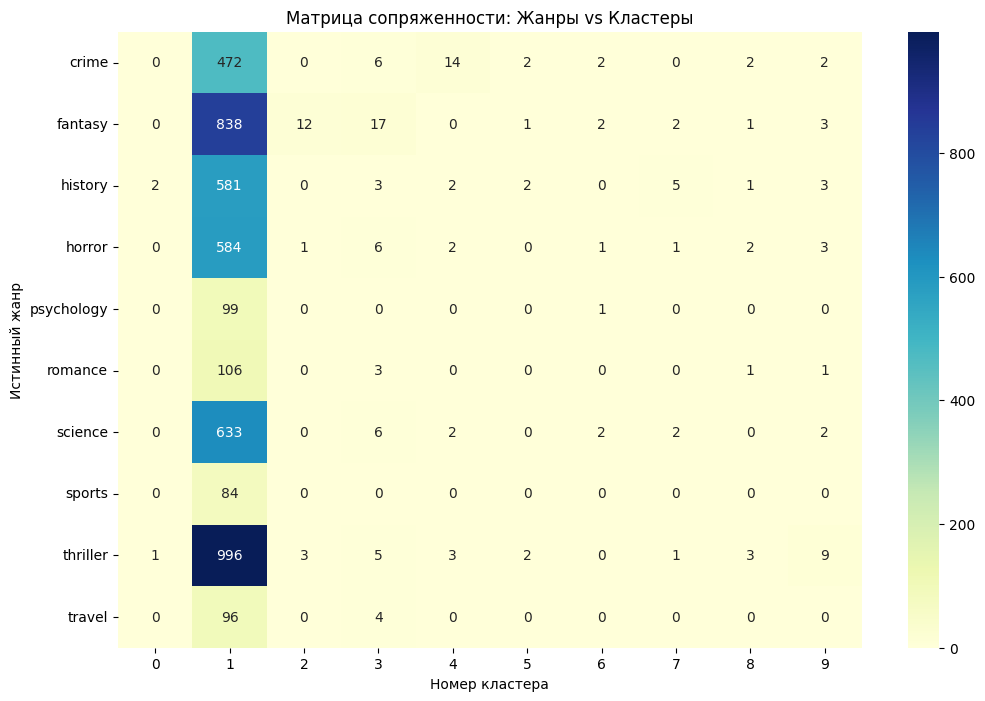

In [51]:
plt.figure(figsize=(12, 8))
sns.heatmap(ct, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Матрица сопряженности: Жанры vs Кластеры')
plt.xlabel('Номер кластера')
plt.ylabel('Истинный жанр')
plt.show()

In [64]:
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('stopwords')

[nltk_data] Downloading package wordnet to /Users/maryc/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /Users/maryc/nltk_data...
[nltk_data] Downloading package stopwords to /Users/maryc/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [65]:
lemmatizer = WordNetLemmatizer()
stop_words_eng = set(stopwords.words('english'))

In [66]:
def advanced_clean_text(text):
    text = str(text).lower() 
    text = re.sub(r'[^a-z\\s]', '', text)
    # Лемматизация и удаление стоп-слов
    words = [lemmatizer.lemmatize(word) for word in text.split() if word not in stop_words_eng]
    return ' '.join(words)

In [76]:
df['lemma_title'] = df['title'].apply(advanced_clean_text)

In [ ]:
tfidf_adv = TfidfVectorizer(
    ngram_range=(1, 2), 
    min_df=2,           
    max_df=0.5,         
    max_features=1500  
)

In [78]:
X_tfidf_adv = tfidf_adv.fit_transform(df['lemma_title'])

In [79]:
X_tfidf_adv.shape

(4640, 311)

Понижение размерности (LSA) Latent Semantic Analysis

In [80]:
svd = TruncatedSVD(n_components=50, random_state=42)

In [81]:
lsa_pipeline = make_pipeline(svd, Normalizer(copy=False))

In [82]:
X_lsa = lsa_pipeline.fit_transform(X_tfidf_adv)

In [83]:
explained_variance = svd.explained_variance_ratio_.sum()

In [84]:
print(f"50 компонент объясняют {explained_variance * 100:.2f}% дисперсии заголовков")

50 компонент объясняют 20.87% дисперсии заголовков


In [85]:
kmeans_lsa = KMeans(n_clusters=10, random_state=42, n_init=10)
df['cluster_lsa'] = kmeans_lsa.fit_predict(X_lsa)

In [88]:
adjusted_rand_score(df['genre'], df['cluster_lsa'])


-0.005568026013208148

In [ ]:
silhouette_score(X_lsa, df['cluster_lsa'])

0.8158215946855958

In [90]:
pca_lsa = PCA(n_components=2, random_state=42)
coords_lsa = pca_lsa.fit_transform(X_lsa)

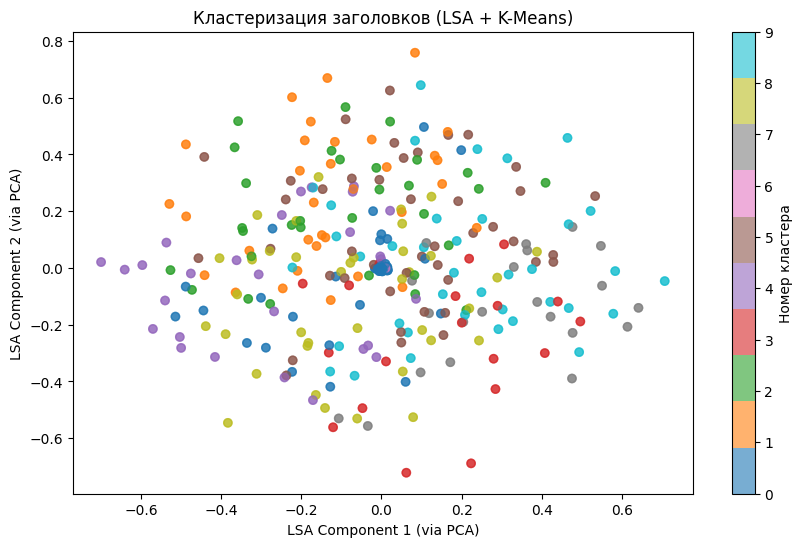

In [92]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(coords_lsa[:, 0], coords_lsa[:, 1], 
                      c=df['cluster_lsa'], cmap='tab10', alpha=0.6)

plt.colorbar(scatter, label='Номер кластера')
plt.title(f"Кластеризация заголовков (LSA + K-Means)")
plt.xlabel("LSA Component 1 (via PCA)")
plt.ylabel("LSA Component 2 (via PCA)")
plt.show()

### Кластеризация по кратким содержаниям

#### Подготовка и кластеризация

In [54]:
df['clean_summary'] = df['summary'].apply(clean_text)

Ограничиваем количество слов до 5000 самых важных

In [55]:
tfidf_sum = TfidfVectorizer(stop_words='english', max_features=5000, min_df=5)
X_sum = tfidf_sum.fit_transform(df['clean_summary'])

In [ ]:
kmeans_sum = KMeans(n_clusters=10, random_state=42, n_init=10)
df['cluster_summary'] = kmeans_sum.fit_predict(X_sum)

In [57]:
adjusted_rand_score(df['genre'], df['cluster_summary'])


0.10050464788644506

In [58]:
pca_sum = PCA(n_components=2)
coords_sum = pca_sum.fit_transform(X_sum.toarray())

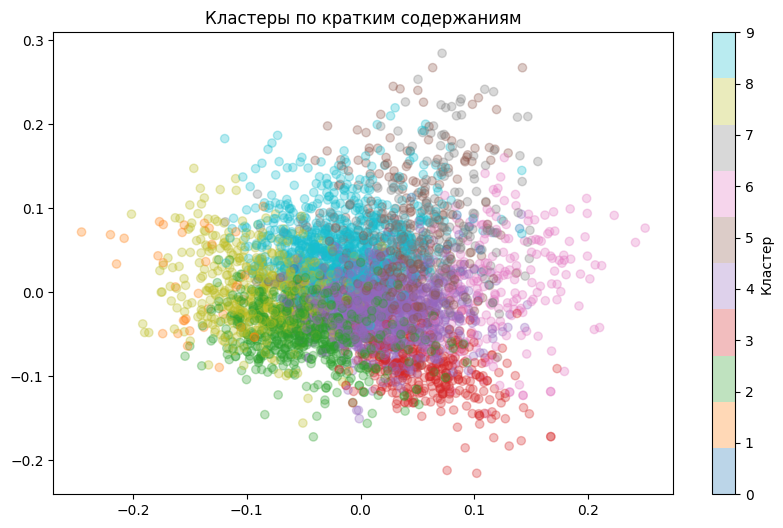

In [60]:
plt.figure(figsize=(10, 6))
plt.scatter(coords_sum[:, 0], coords_sum[:, 1], c=df['cluster_summary'], cmap='tab10', alpha=0.3)
plt.title(f"Кластеры по кратким содержаниям")
plt.colorbar(label='Кластер')
plt.show()

Генерация облаков слов для кластеров SUMMARY...


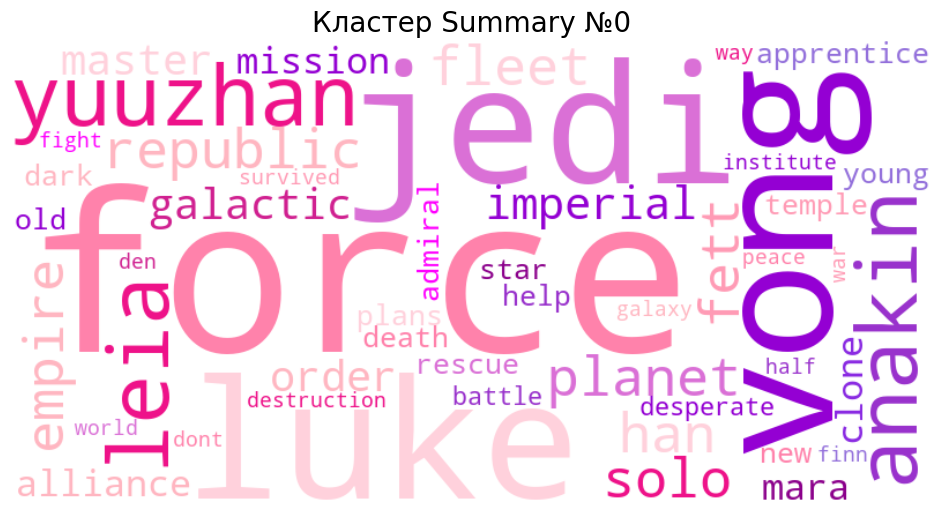

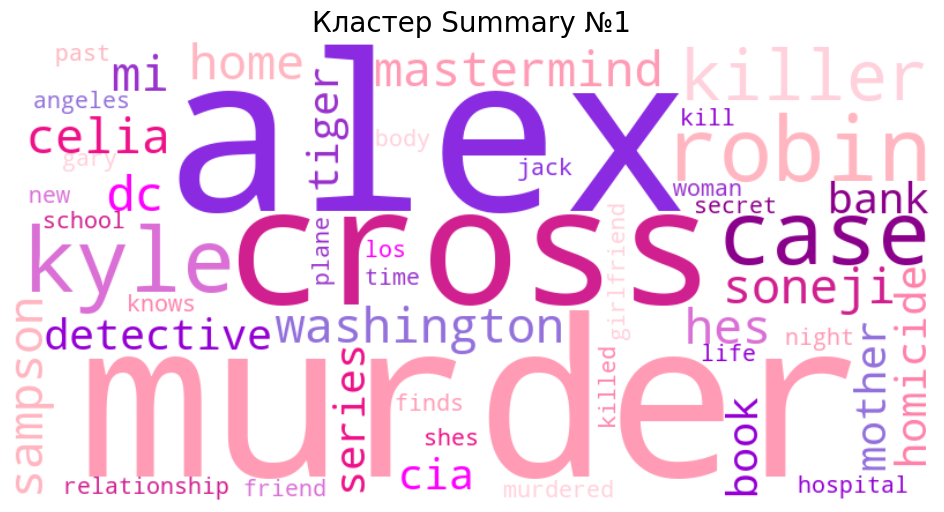

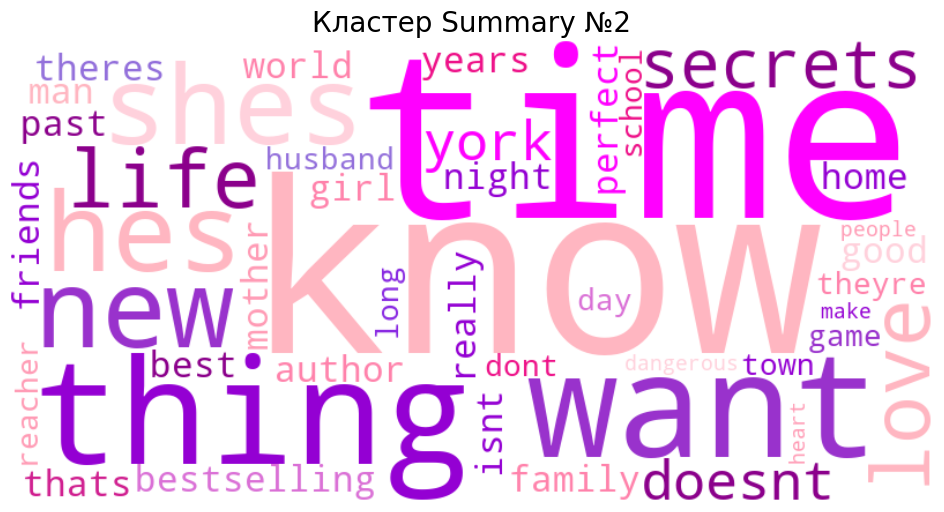

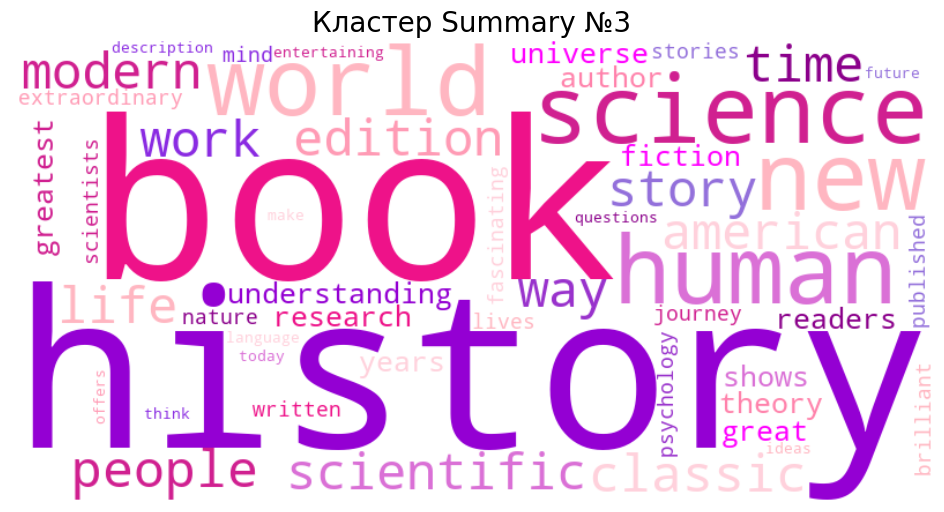

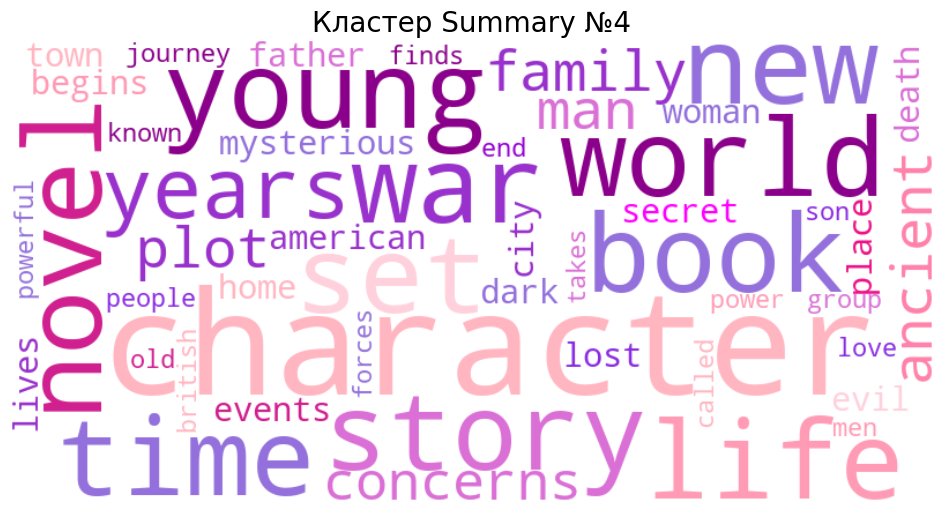

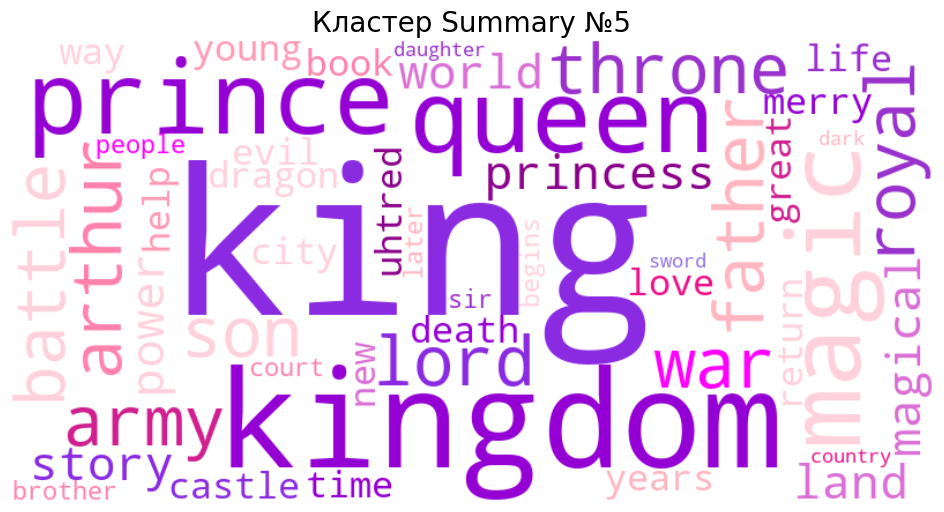

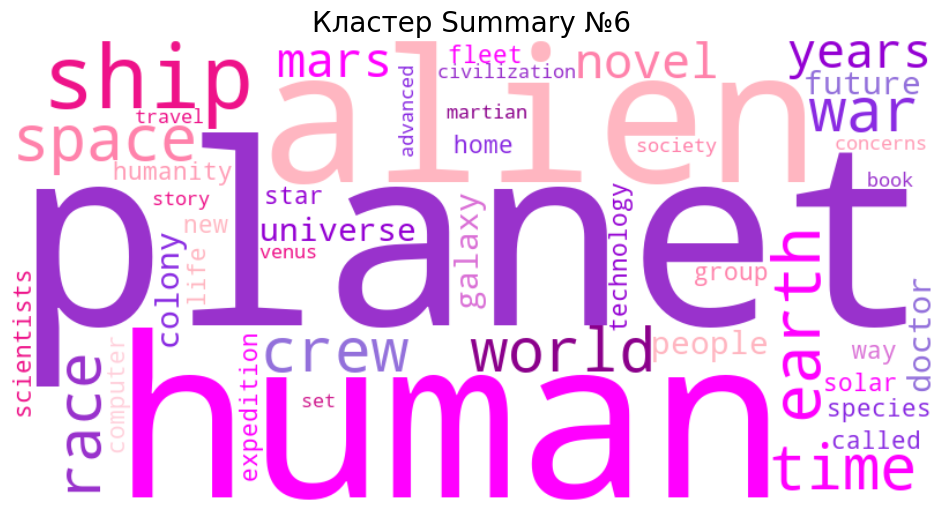

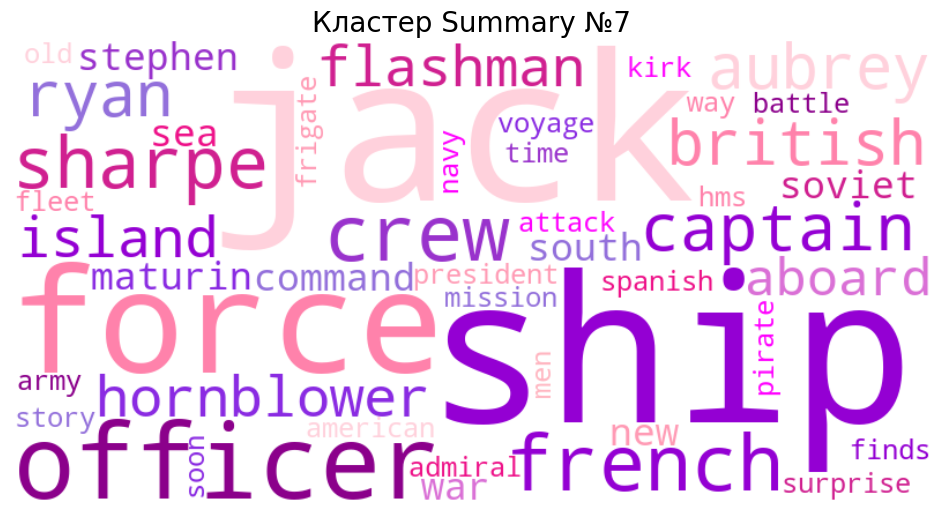

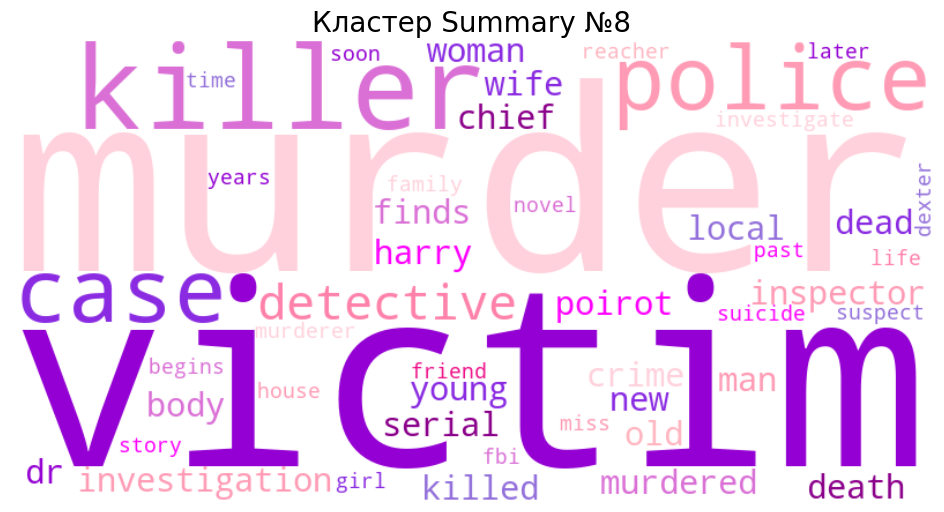

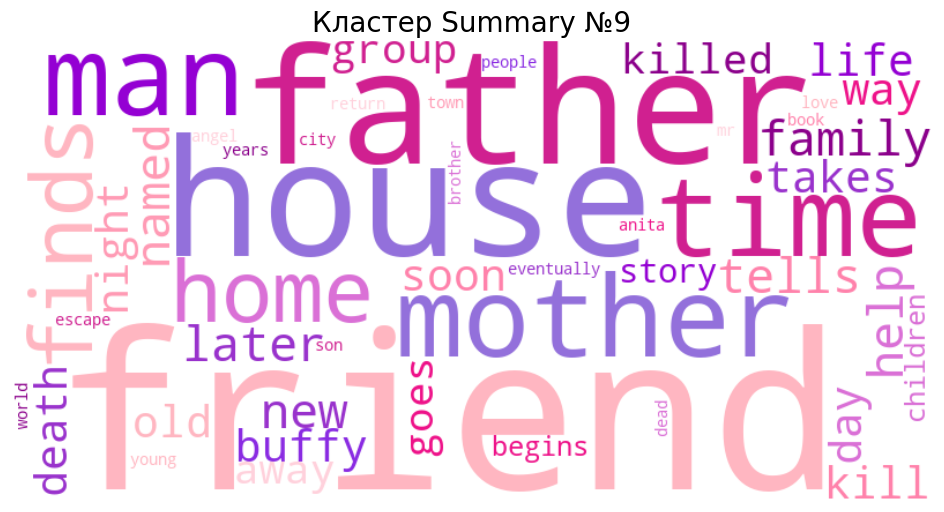

In [ ]:
feature_names_sum = tfidf_sum.get_feature_names_out()


for i in range(10):
    indices = (df['cluster_summary'] == i).values
    cluster_data = X_sum[indices]
    
    if cluster_data.shape[0] > 0:
        weights = cluster_data.mean(axis=0).A1
        top_indices = weights.argsort()[::-1][:50] 
        words_to_plot = [feature_names_sum[idx] for idx in top_indices]
        
        plot_wordcloud(words_to_plot, f"Кластер Summary №{i}")

In [61]:
ct = pd.crosstab(df['genre'], df['cluster_summary'])

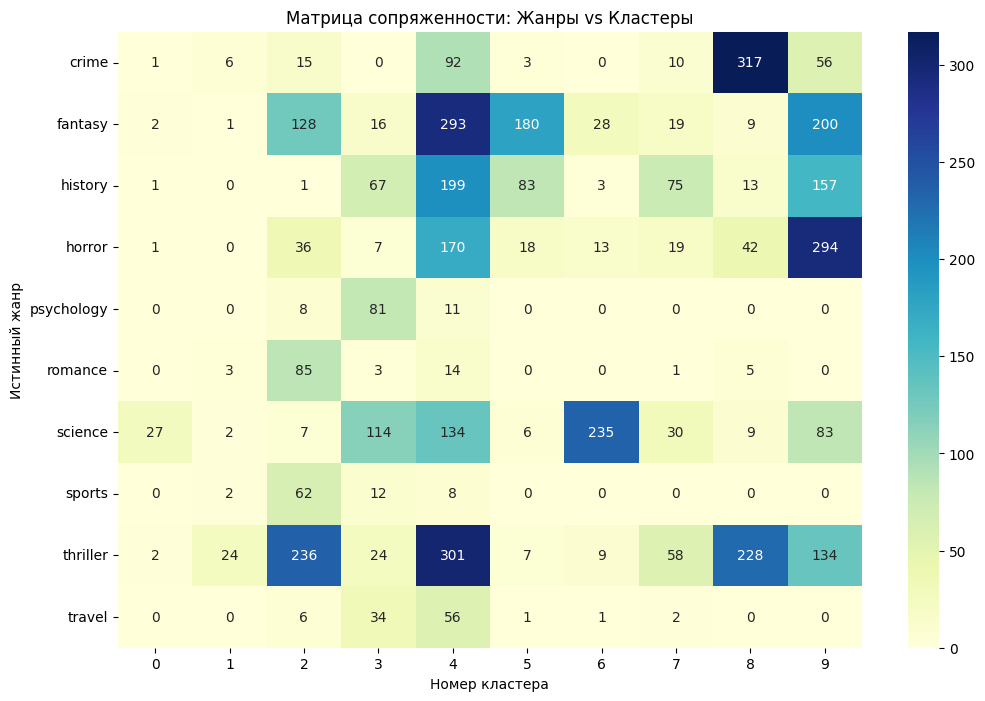

In [62]:
plt.figure(figsize=(12, 8))
sns.heatmap(ct, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Матрица сопряженности: Жанры vs Кластеры')
plt.xlabel('Номер кластера')
plt.ylabel('Истинный жанр')
plt.show()

In [93]:
for i in range(10):
    cluster_indices = (df['cluster_summary'] == i).values
    
    # Выбираем строки текущего кластера
    cluster_matrix = X_ngram[cluster_indices]
    
    if cluster_matrix.shape[0] > 0:
        # Считаем среднее значение весов для каждого слова
        mean_weights = cluster_matrix.mean(axis=0).A1
        # Сортируем и берем топ-5 слов
        top_indices = mean_weights.argsort()[::-1][:5]
        
        print(f"Кластер {i}: {', '.join([words[idx] for idx in top_indices])}")
    else:
        print(f"Кластер {i}: пустой")

Кластер 0: jedi, force, star, shadow, dark
Кластер 1: cross, blue, red, ninth, roses
Кластер 2: girl, girls, good, love, city
Кластер 3: history, world, life, science, time
Кластер 4: night, dark, book, death, dead
Кластер 5: king, queen, prince, war, kings
Кластер 6: space, stars, star, world, war
Кластер 7: sharpes, flashman, hornblower, ship, enemy
Кластер 8: death, murder, man, house, dexter
Кластер 9: dark, blood, house, dead, night
